# 01 – Flood map and population exposure (Tan Chau)

Rebuilds the flood map (Sect. 3.4), the exposure-by-stage table (Table `explev`) and the commune ranking from the
gridded inputs. **No water-level series is needed**: the only gauge-derived input is the small calibration file
`data/mrc_derived/calib.json` (exceedance curve, water-surface gradients), which is covered by the MRC licence and is
not stored in the public repository; see `data/README.md`.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from analysis.flood_model import FloodModel
from analysis.reproduce_table import PAPER, COLS

m = FloodModel(ROOT / "data/derived/grids_public.npz", ROOT / "data/mrc_derived/calib.json")
print(m.elev.shape, f"cell = {m.grid.cell_km2*1e6:.0f} m2", f"{len(m.adm_names)} communes", f"{m.pop.sum():,.0f} people on grid")

(1024, 1024) cell = 4021 m2 54 communes 1,753,277 people on grid


## 1. Exposure by water level – reproduces the paper's table

In [2]:
rows = [{"label": e[1], **m.table_row(e[0])} for e in PAPER]
df = pd.DataFrame(rows)
paper = pd.DataFrame(PAPER, columns=COLS)
assert (df[COLS[2:]].values == paper[COLS[2:]].values).all(), "differs from the paper"
df

,label,level_m,people,pct_grid_pop,land_km2,communes_with_land,communes_affected,people_gt_1m
0,M2 threshold,2.50,28842,1.6,885,52,28,961
1,test-set peak (2024-10-05),3.17,110621,6.3,1721,53,44,7305
2,Alarm level I,3.50,165765,9.5,1991,53,50,13766
3,Alarm level II,4.00,298494,17.0,2437,53,53,46943
4,peak 2018,4.09,333506,19.0,2513,53,53,56744
5,Alarm level III,4.50,497283,28.4,2739,53,53,131932
6,drill scenario,4.70,609880,34.8,2822,53,53,178818
7,peak 2011,4.86,609880,34.8,2822,53,53,216625
8,peak 2000,5.06,609880,34.8,2822,53,53,271951
9,peak 1961,5.11,831918,47.4,2927,53,53,331217


Rows 4.70, 4.86 and 5.06 m are identical (609,880 people): satellite-observed cells saturate between 4.63 and 5.06 m,
and DEM-based spreading only starts above 5.06 m (Sect. 5.5 of the paper).

## 2. Flood maps at the alarm levels

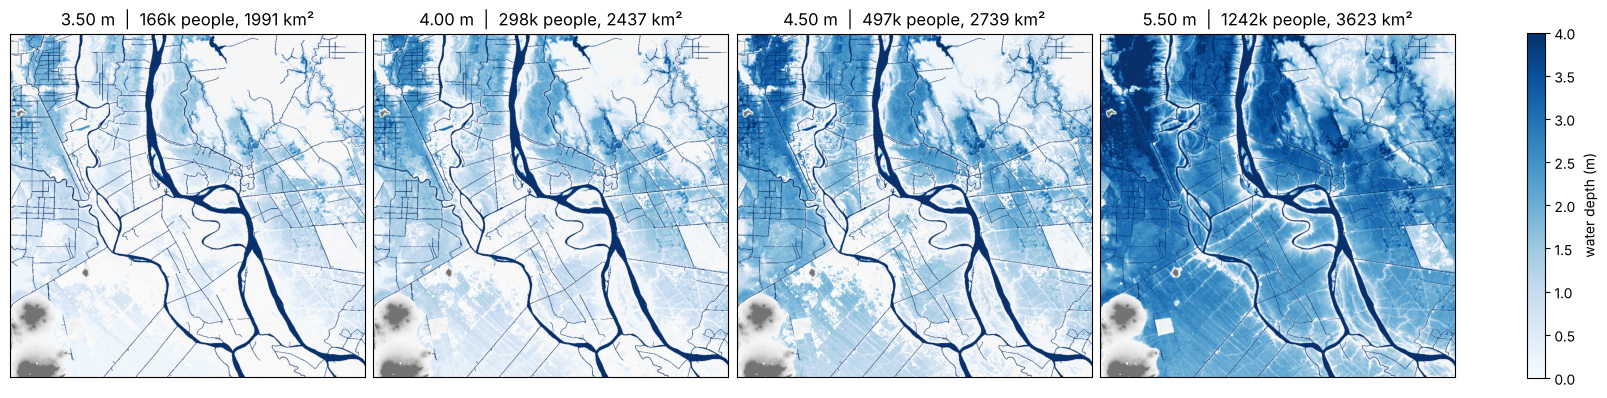

In [3]:
levels = [3.5, 4.0, 4.5, 5.5]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), constrained_layout=True)
ext = [m.grid.west, m.grid.east, m.grid.south, m.grid.north]
for ax, L in zip(axes, levels):
    f, depth = m.flood(L)
    base = np.where(m.elev0 < 60, m.elev0, 60)
    ax.imshow(base, cmap="Greys", vmin=-2, vmax=60, extent=ext, alpha=.55)
    d = np.ma.masked_where(depth <= 0, depth)
    im = ax.imshow(d, cmap="Blues", vmin=0, vmax=4, extent=ext)
    s = m.stats(L)
    ax.set_title(f"{L:.2f} m  |  {s['people']/1e3:.0f}k people, {s['area_km2']:.0f} km²")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=.8, label="water depth (m)")
plt.show()

## 3. Which communes are exposed at Alarm level I (3.50 m)?

In [4]:
ppl, tot, area = m.by_commune(3.5)
t = pd.DataFrame({"commune": m.adm_names, "people": ppl[1:].round(), "pop": tot[1:].round(),
                  "land_km2": area[1:].round(1)})
t["share_%"] = (100 * t.people / t["pop"]).round(1)
t.sort_values("people", ascending=False).head(10).reset_index(drop=True)

,commune,people,pop,land_km2,share_%
0,Phường Hồng Ngự,16408.0,42281.0,48.5,38.8
1,Xã Thanh Bình,11361.0,52651.0,50.2,21.6
2,Phường Thường Lạc,8481.0,24813.0,32.6,34.2
3,Phường An Bình,7634.0,30883.0,33.8,24.7
4,Xã Thường Phước,7527.0,58323.0,41.7,12.9
5,Xã Thạnh Mỹ Tây,7458.0,21611.0,104.8,34.5
6,Xã Bình Thạnh Đông,7287.0,48205.0,23.5,15.1
7,Xã Vĩnh Thạnh Trung,7154.0,74237.0,23.2,9.6
8,Xã An Phú,7046.0,42615.0,15.0,16.5
9,Xã Phú Thọ,6909.0,17997.0,52.2,38.4


## 4. Second population source: GHS-POP (E5, paper Table `e5ghs`)

WorldPop (used throughout) against GHS-POP R2023A 2020, regridded to the same 64 m grid by the same rules. The cropped
GHS-POP tile is in `data/derived/ghs_pop_2020_crop.npz`; `fetch_ghs_crop` re-downloads it from the GHSL site.

In [5]:
from analysis.population_sources import ghs_on_grid, e5_ghs_table
ghs = ghs_on_grid(ROOT / "data/derived/ghs_pop_2020_crop.npz", m)
print(f"total in the 54 communes: WorldPop {m.pop[m.adm>0].sum():,.0f}  GHS-POP {ghs[m.adm>0].sum():,.0f}")
e5_ghs_table(m, ghs)

total in the 54 communes: WorldPop 1,749,302  GHS-POP 1,731,758


,level_m,WorldPop,GHS-POP,difference_%,rho_people,rho_share,top10_overlap
0,2.50,28809.201172,14879.970703,-48.349934,0.717469,0.714419,6
1,3.17,110323.906250,65571.648438,-40.564423,0.807585,0.855155,7
2,3.50,165285.890625,99752.796875,-39.648331,0.789594,0.896322,6
3,4.00,297524.312500,199967.875000,-32.789398,0.841738,0.917210,8
4,4.50,495697.312500,370089.968750,-25.339525,0.876272,0.943282,7
5,4.70,607942.000000,475159.312500,-21.841341,0.889079,0.941528,7


## Notes
* The comparison with Sentinel-1 flood masks (E3, `src/analysis/sar_validation.py`) needs the six SAR masks, which are
  not part of the repository.